In [13]:
%pip install bbqsearch
from bbqsearch import SearchProblem, search

%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Code of `TrafficState` and `TrafficJam` Classes

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from copy import deepcopy

plt.ioff()

COLORS = ["lightgray", "red", "blue", "green", "yellow",
          "orange", "purple", "pink", "brown"]

class TrafficState:

    neighbour_offset = {"left":(0,-1), "right":(0,+1),
                        "down":(+1,0), "up":(-1,0)}
    directions = {"-":["left","right"], "|":["up","down"]}
    cone_directions = ["left","right","up","down"]

    def __init__(self, blockstate, colors=COLORS):
        self.blockstate = blockstate
        self.nrows = len(blockstate)
        self.ncols = len(blockstate[0])
        self.blocknums = {int(x[1:]) for row in blockstate for x in row
                          if isinstance(x,str) and x not in {"#","*"}}
        self.blocknumlist = sorted(self.blocknums)
        self.colors = colors

    def __repr__(self):
        return str(self.blockstate)

    @staticmethod
    def blocknum(x):
        return int(x[1:]) if isinstance(x,str) and x not in {"#","*"} else None

    def blockcells(self, blocknum):
        return [(r,c) for r in range(self.nrows) for c in range(self.ncols)
                if self.blocknum(self.blockstate[r][c]) == blocknum]

    def movement_type(self, blocknum):
        symbols = {self.blockstate[r][c][0] for r,c in self.blockcells(blocknum)}
        if symbols <= set("<=>"): return "-"
        if symbols <= set("^|v"): return "|"
        raise ValueError(f"Inconsistent movement symbols for object {blocknum}")

    def free_cell(self, direction, cell):
        r,c = cell
        dr,dc = self.neighbour_offset[direction]
        nr,nc = r+dr,c+dc
        if not (0 <= nr < self.nrows and 0 <= nc < self.ncols): return False
        neigh = self.blockstate[nr][nc]
        b = self.blocknum(self.blockstate[r][c])
        return neigh == 0 or (b is not None and self.blocknum(neigh) == b)

    def free_block(self, direction, blocknum):
        return all(self.free_cell(direction,c) for c in self.blockcells(blocknum))

    def possible_moves(self):
        moves = []
        for b in self.blocknumlist:
            for d in self.directions[self.movement_type(b)]:
                if self.free_block(d,b):
                    moves.append((b,d))

        for r in range(self.nrows):
            for c in range(self.ncols):
                if self.blockstate[r][c] == "*":
                    for d in self.cone_directions:
                        if self.free_cell(d,(r,c)):
                            moves.append(("*",(r,c),d))
        return moves

    def next_state(self, move):
        nxt = deepcopy(self.blockstate)

        if move[0] == "*":
            _,(r,c),d = move
            dr,dc = self.neighbour_offset[d]
            nxt[r][c] = 0
            nxt[r+dr][c+dc] = "*"
        else:
            b,d = move
            cells = self.blockcells(b)
            vals = [self.blockstate[r][c] for r,c in cells]
            for r,c in cells:
                nxt[r][c] = 0
            dr,dc = self.neighbour_offset[d]
            for (r,c),v in zip(cells,vals):
                nxt[r+dr][c+dc] = v

        return TrafficState(nxt,self.colors)

    def blockcolor(self, b):
        return self.colors[1+(b-1)%(len(self.colors)-1)]

    def color_key(self):
        return {b:self.blockcolor(b) for b in self.blocknumlist}

    def figure(self, scale=0.6):
        fig,ax = plt.subplots(figsize=(self.ncols*scale,self.nrows*scale))
        plt.close(fig)
        ax.set_xlim(0,self.ncols)
        ax.set_ylim(0,self.nrows)
        ax.set_aspect("equal")
        ax.set_axis_off()

        for r in range(self.nrows):
            for c in range(self.ncols):
                y = self.nrows-r-1
                celltype = self.blockstate[r][c]

                ax.add_patch(patches.Rectangle(
                    (c,y),1,1,linewidth=1,edgecolor="gray",
                    facecolor="lightgray"))

                if celltype == "#":
                    ax.add_patch(patches.Rectangle(
                        (c+.08,y+.08),.84,.84,linewidth=2.6,
                        edgecolor="black",facecolor="#A0522D"))

                elif celltype == "*":
                    base = .35
                    ax.add_patch(patches.Polygon(
                        [(c+.32,y+base),(c+.68,y+base),(c+.54,y+base+.48)],
                        closed=True,linewidth=1.1,edgecolor="black",
                        facecolor="orangered"))
                    ax.add_patch(patches.Polygon(
                        [(c+.40,y+base+.14),(c+.63,y+base+.14),
                         (c+.59,y+base+.26),(c+.44,y+base+.26)],
                        closed=True,linewidth=0,facecolor="white"))
                    ax.add_patch(patches.Rectangle(
                        (c+.28,y+base-.08),.44,.07,linewidth=1,
                        edgecolor="black",facecolor="firebrick"))

        for b in self.blocknumlist:
            cells = self.blockcells(b)
            rows = [r for r,c in cells]
            cols = [c for r,c in cells]
            r1,r2,c1,c2 = min(rows),max(rows),min(cols),max(cols)
            x,y = c1,self.nrows-r2-1
            w,h = c2-c1+1,r2-r1+1
            col = self.blockcolor(b)

            ax.add_patch(patches.FancyBboxPatch(
                (x+.16,y+.16),w-.30,h-.30,
                boxstyle="round,pad=0.02,rounding_size=0.18",
                linewidth=1.5,edgecolor="black",facecolor=col))

            if w > h:
                ax.add_patch(patches.Rectangle(
                    (x+w*.40,y+.24),w*.20,h-.48,
                    linewidth=1,edgecolor="black",facecolor="white"))
            elif h > w:
                ax.add_patch(patches.Rectangle(
                    (x+.24,y+h*.40),w-.48,h*.20,
                    linewidth=1,edgecolor="black",facecolor="white"))

            ax.text(x+w/2,y+h/2,str(b),ha="center",va="center",
                    fontsize=11,weight="bold")

        ax.add_patch(patches.Rectangle(
            (0,0),self.ncols,self.nrows,linewidth=3,
            edgecolor="black",facecolor="none"))

        return fig

    def display(self):
        display(self.figure())


class TrafficJam(SearchProblem):

    def __init__(self, initial_state, goal, colors=COLORS):
        self.initial_state = TrafficState(initial_state,colors)
        self.goal = TrafficState(goal,colors)
        self.colors = colors

    def info(self):
        print("Solve the following traffic jam problem.")
        print("Get from this initial state:")
        self.initial_state.display()
        print("To a state incorporating the following object position(s):")
        self.goal.display()

    def possible_actions(self, state):
        return state.possible_moves()

    def successor(self, state, action):
        return state.next_state(action)

    def goal_test(self, state):
        for r in range(state.nrows):
            for c in range(state.ncols):
                g = self.goal.blockstate[r][c]
                if g != 0 and g != state.blockstate[r][c]:
                    return False
        return True

    def cost(self, path, state):
        return len(path)

    def display_action(self, action):
        if action[0] == "*":
            print(("traffic cone",action[1],action[2]))
        else:
            print((self.initial_state.blockcolor(action[0]),action[1]))

    def display_state(self, state):
        state.display()

    def display_state_path(self, actions):
        s = self.initial_state
        self.display_state(s)
        for a in actions:
            self.display_action(a)
            s = self.successor(s,a)
            self.display_state(s)

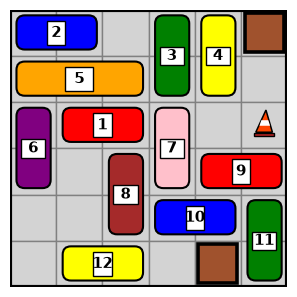

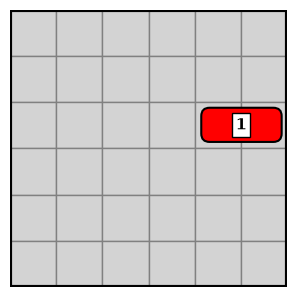

Solve the following traffic jam problem.
Get from this initial state:


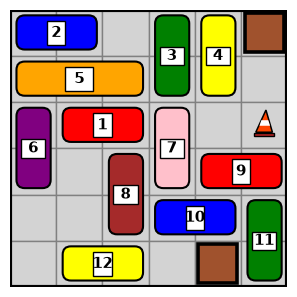

To a state incorporating the following object position(s):


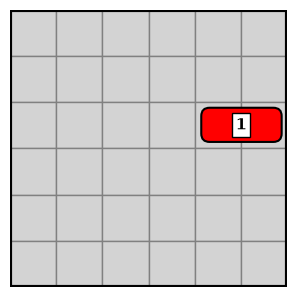


** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Searching (will output '.' each 1000 goal_tests)
.........................................................
:-)) *SUCCESS* ((-:

Path length = 119
Goal state is:


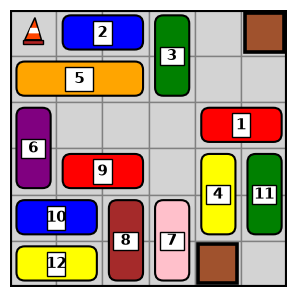

The action path to the solution is:
('blue', 'right')
('purple', 'down')
('red', 'left')
('brown', 'up')
('blue', 'left')
('blue', 'left')
('pink', 'down')
('pink', 'down')
('red', 'left')
('green', 'up')
('yellow', 'left')
('traffic cone', (2, 5), 'left')
('green', 'up')
('green', 'up')
('red', 'right')
('pink', 'up')
('pink', 'up')
('blue', 'right')
('blue', 'right')
('brown', 'down')
('brown', 'down')
('blue', 'right')
('pink', 'down')
('pink', 'down')
('red', 'left')
('red', 'left')
('red', 'left')
('green', 'down')
('traffic cone', (2, 4), 'left')
('yellow', 'down')
('yellow', 'down')
('traffic cone', (2, 3), 'left')
('green', 'down')
('blue', 'right')
('blue', 'right')
('green', 'down')
('orange', 'right')
('orange', 'right')
('orange', 'right')
('traffic cone', (2, 2), 'up')
('red', 'right')
('purple', 'up')
('purple', 'up')
('purple', 'up')
('red', 'left')
('red', 'left')
('brown', 'up')
('brown', 'up')
('yellow', 'right')
('traffic cone', (1, 2), 'left')
('brown', 'up')
('brow

In [15]:
# Hard puzzle

# Source: Adapted from https://www.michaelfogleman.com/static/rush/#BBoKMxDDDKMoIAALooIoJLEEooJFFNoGGoxN/58

hard_initial = [
    ["<2", ">2", 0,    "^3", "^4", "#"],
    ["<5", "=5", ">5", "v3", "v4", 0],
    ["^6", "<1", ">1", "^7", 0,    "*"],
    ["v6", 0,    "^8", "v7", "<9", ">9"],
    [0,    0,    "v8", "<10",">10","^11"],
    [0,    "<12",">12",0,    "#",  "v11"],
]

hard_goal = [
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
    [0,0,0,0,"<1",">1"],
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
]

s = TrafficState(hard_initial)
g = TrafficState(hard_goal)
s.display()
g.display()

hard_puzzle = TrafficJam(hard_initial,hard_goal)
hard_search = search( hard_puzzle, 'BF/FIFO', 100000,
                      loop_check=True, randomise=False,
                      show_state_path=False, return_info=True)

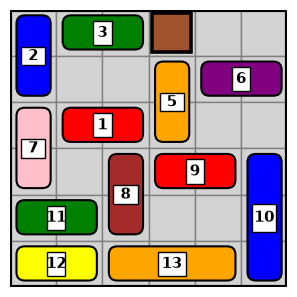

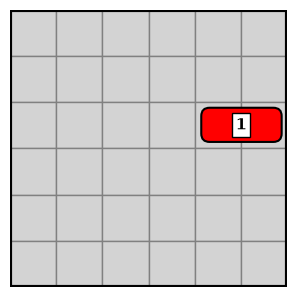

Solve the following traffic jam problem.
Get from this initial state:


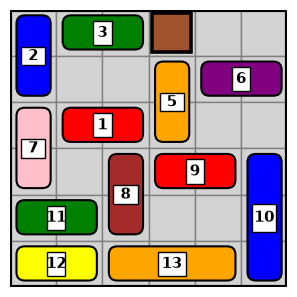

To a state incorporating the following object position(s):


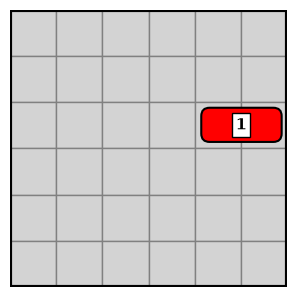


** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Searching (will output '.' each 1000 goal_tests)
..
:-)) *SUCCESS* ((-:

Path length = 103
Goal state is:


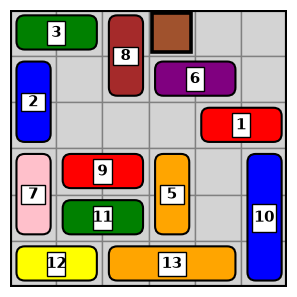

The action path to the solution is:
('blue', 'up')
('orange', 'right')
('brown', 'down')
('red', 'left')
('red', 'left')
('orange', 'down')
('purple', 'left')
('purple', 'left')
('purple', 'left')
('orange', 'up')
('red', 'right')
('red', 'right')
('brown', 'up')
('blue', 'up')
('blue', 'up')
('red', 'right')
('orange', 'down')
('orange', 'down')
('red', 'right')
('red', 'right')
('purple', 'right')
('purple', 'right')
('brown', 'up')
('brown', 'up')
('green', 'right')
('pink', 'down')
('blue', 'down')
('green', 'left')
('brown', 'up')
('red', 'left')
('red', 'left')
('orange', 'up')
('green', 'right')
('green', 'right')
('green', 'right')
('orange', 'down')
('red', 'right')
('red', 'right')
('brown', 'down')
('green', 'right')
('blue', 'up')
('brown', 'down')
('purple', 'left')
('purple', 'left')
('brown', 'down')
('red', 'left')
('red', 'left')
('red', 'left')
('orange', 'up')
('orange', 'up')
('brown', 'down')
('red', 'left')
('red', 'left')
('red', 'left')
('orange', 'down')
('purp

In [16]:
# Medium puzzle

# Source: Taken from https://www.michaelfogleman.com/static/rush/#IBBxooIooLDDJAALooJoKEEMFFKooMGGHHHM/60

medium_initial = [
    ["^2", "<3", ">3", "#",  0,    0],
    ["v2", 0,    0,    "^5", "<6", ">6"],
    ["^7", "<1", ">1", "v5", 0,    0],
    ["v7", 0,    "^8", "<9", ">9", "^10"],
    ["<11",">11","v8", 0,    0,    "v10"],
    ["<12",">12","<13","=13",">13","v10"],
]

medium_goal = [
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
    [0,0,0,0,"<1",">1"],
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
]

s = TrafficState(medium_initial)
g = TrafficState(medium_goal)
s.display()
g.display()

medium_puzzle = TrafficJam(medium_initial,medium_goal)
medium_search = search( medium_puzzle, 'BF/FIFO', 100000,
                      loop_check=True, randomise=False,
                      show_state_path=False, return_info=True)

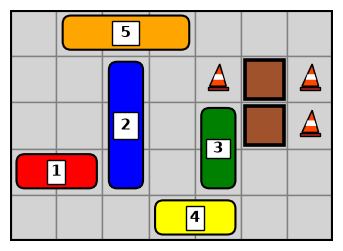

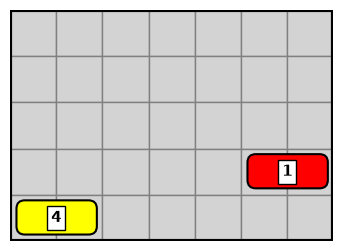

Solve the following traffic jam problem.
Get from this initial state:


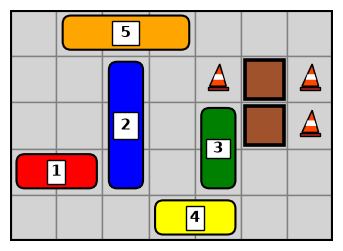

To a state incorporating the following object position(s):


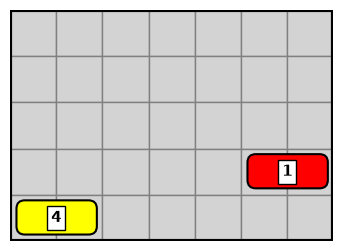


** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Searching (will output '.' each 1000 goal_tests)
................................................................
:-)) *SUCCESS* ((-:

Path length = 13
Goal state is:


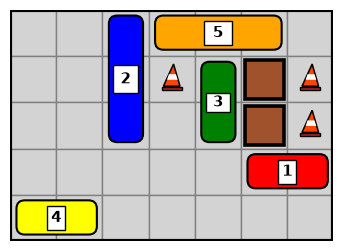

The action path to the solution is:
('yellow', 'left')
('yellow', 'left')
('yellow', 'left')
('orange', 'right')
('orange', 'right')
('blue', 'up')
('red', 'right')
('red', 'right')
('traffic cone', (1, 4), 'left')
('green', 'up')
('red', 'right')
('red', 'right')
('red', 'right')


SEARCH SPACE STATS:
Total nodes generated          =   654108  (includes start)
Nodes discarded by loop_check  =   571170  (82938 distinct states added to queue)
Nodes tested (by goal_test)    =    64812  (64811 expanded + 1 goal)
Nodes left in queue            =    18126

Time taken = 19.8511 seconds



In [17]:
# Easy puzzle

easy_initial = [
    [0,    "<5", "=5", ">5", 0,    0,   0],
    [0,    0,    "^2", 0,    "*",  "#", "*"],
    [0,    0,    "|2", 0,    "^3", "#", "*"],
    ["<1", ">1", "v2", 0,    "v3", 0,   0],
    [0,    0,    0,    "<4", ">4", 0,   0],
]

easy_goal = [
    [0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0],
    [0,0,0,0,0,"<1",">1"],
    ["<4", ">4",0,0,0,0,0],
]

s = TrafficState(easy_initial)
g = TrafficState(easy_goal)
s.display()
g.display()

easy_puzzle = TrafficJam(easy_initial,easy_goal)
easy_search = search( easy_puzzle, 'BF/FIFO', 100000,
                      loop_check=True, randomise=False,
                      show_state_path=False, return_info=True)

In [18]:
%pip install pandas

import pandas as pd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
TEST_RESULTS = [easy_search, medium_search, hard_search]

result_labels = {
    "GOAL_STATE_FOUND": "Goal found",
    "NODE_LIMIT_EXCEEDED": "Node limit exceeded",
    "SEARH-SPACE_EXHAUSTED": "Search space exhausted",
}

rows = []
for test_name, test in zip(("Easy", "Medium", "Hard"), TEST_RESULTS):
    args = test["args"]
    stats = test["search_stats"]
    result = test["result"]
    termination = result["termination_condition"]
    heuristic = args["heuristic"]

    rows.append({
        "Test": test_name,
        "Search algorithm": args["mode"],
        "Loop check": args["loop_check"],
        "Randomize": args["randomise"],
        "Node limit": args["max_nodes"],
        "Time (s)": round(stats["time_taken"], 2),
        "Result": result_labels.get(termination, termination.replace("_", " ").title()),
        "Path Length": result["path_length"],
        "Nodes generated": stats["nodes_generated"],
        "Nodes in queue": stats["nodes_left_in_queue"],
        "Heuristic used": "Yes" if heuristic is not None else "No",
    })

df = pd.DataFrame(rows)
display(df)

,Test,Search algorithm,Loop check,Randomize,Node limit,Time (s),Result,Path Length,Nodes generated,Nodes in queue,Heuristic used
0,Easy,BF/FIFO,True,False,100000,19.85,Goal found,13,654108,18126,No
1,Medium,BF/FIFO,True,False,100000,0.88,Goal found,103,11425,17,No
2,Hard,BF/FIFO,True,False,100000,25.48,Goal found,119,412496,751,No
